|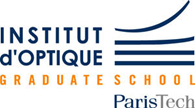|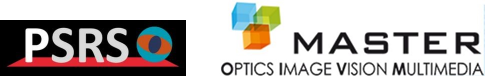|
|:--:|:--:|

# Digital Holography : numerical simulation and reconstruction
# Lab 1 - Discrete Fourier Transform and spectrum analysis


***


Python will be used to simulate, process, and display physical optics signals. The Python functions to be used are given in the lab text. You will need to read the  help for their syntax (Use the window contextual help). 

For each lab session, a fill-in-the-blank code will be provided to you in order to start the practical work. You will rename it (SURNAME_Lab1.ipynb) and publish a report that will be uploaded on Moodle. 

It is mandatory to annotate/comment your code. 
Two lab reports will be uploaded on Moodle : one at the end of the session and another one (completed) before the next session. It will contain the programs/functions and the images results as well as your comments. It should be personal. 

+++ questions are optional.

***


In [74]:
# %matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

plt.rcParams["figure.figsize"] = (8,4) # choose the size of the figures : Width, height in inches.

## 1. 2D Discrete Fourier Transform (DFT)

### 1.1. Display of the images `sinus.png` and its spectrum

#### a. Using the code below :

Load in the workspace the image `sinus.png` (`cv.imread(path,cv.IMREAD_GRAYSCALE)` see Lab0_Main_example). Convert in double type the image matrix (`np.double`). Display the image (`plt.imshow`). 

Add code in order to display labels to abscissa and ordinate axis (the units have to be given, here "x(pix)", "y(pix)"

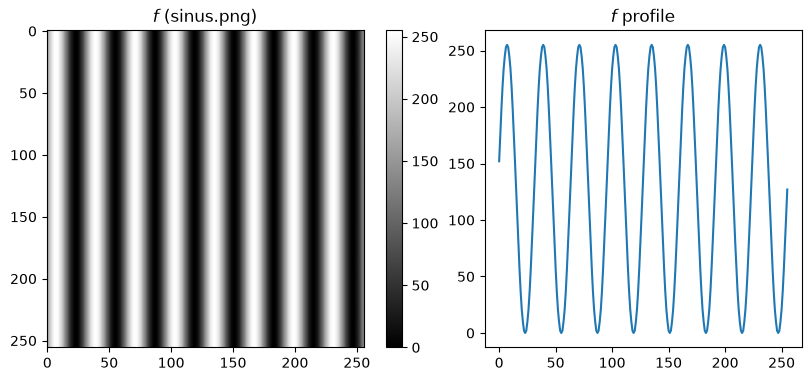

In [75]:
I=cv.imread('Lab1_Images/sinus.png',cv.IMREAD_GRAYSCALE) 
I=np.double(I)

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(I,'gray')
plt.colorbar()
plt.title('$f$ (sinus.png)')

plt.subplot(1,2,2)
plt.plot(I[0,:])
plt.title('$f$ profile')

plt.show()

#### b. Compute its spectrum (`np.fft.fft2`)

In [76]:
FFT_I=np.fft.fft2(I)

The frequency (0,0) is located in the top left corner of the Fourier spectrum. The signal is real, its Fourier transform modulus should be complex and even.

#### c. Compute and display its phase and its modulus (angle, abs) 

By default the origin of the frequencies axis is on the left top corner and we visualize frequencies: $0 \leq \mu_x < 1$, $0 \leq \mu_y <1$). We have to center the origin using fftshift in order to visualize $-1/2 \leq \mu_x < 1/2$, $-1/2 \leq \mu_y < 1/2$. 

Understand, comment and use the following code (FFTimg contains the 2D DFT of the image):

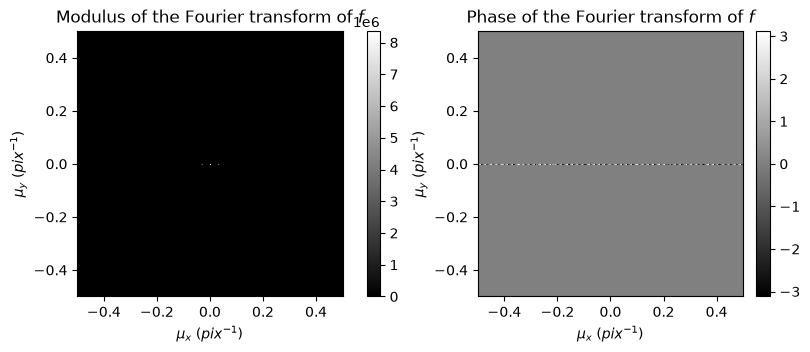

In [77]:
DISPLAY_FFT_I=np.fft.fftshift(FFT_I) # Shift of the spectrum FFTimg

MODULUS_DISPLAY_FFT_I=np.abs(DISPLAY_FFT_I)
PHASE_DISPLAY_FFT_I=np.angle(DISPLAY_FFT_I)

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(MODULUS_DISPLAY_FFT_I,extent=[-1/2,1/2,-1/2,1/2],cmap='gray')
plt.colorbar() # creates a color bar lookup table of the cmapxœ
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)')
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=[-1/2,1/2,-1/2,1/2],cmap='gray')
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')

plt.show()

#### d. Let’s consider that pixel width is 5 µm. Display again the spectrum using frequency units in m-1. 

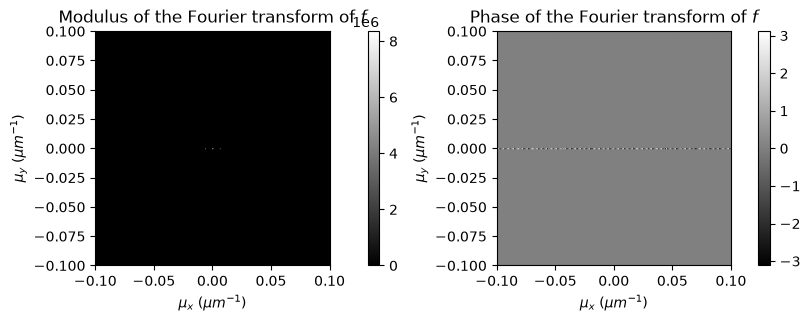

In [78]:
DISPLAY_FFT_I=np.fft.fftshift(FFT_I) # Shift of the spectrum FFTimg

MODULUS_DISPLAY_FFT_I=np.abs(DISPLAY_FFT_I)
PHASE_DISPLAY_FFT_I=np.angle(DISPLAY_FFT_I)

div = 5
extent = [-1/2 / div,1/2 / div,-1/2 / div,1/2 / div]

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(MODULUS_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar() # creates a color bar lookup table of the cmapxœ
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($\mu m^{-1}$)')
plt.ylabel(r'$\mu_y$ ($\mu m^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($\mu m^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($\mu m^{-1}$)')

plt.show()

### 1.2. Spectrum analysis

#### a. Analyse the spectrum modulus (`np.abs`) and its phase (`np.angle`)

### Modulus Analysis
There are three peaks, the lateral peaks correspond to the sine function while the central peak corresponds to the zero frequency

the lateral peaks correspond to  8

$f(x)=127.5 sin(2 \pi x \mu) + 127.5$

127.5 * 256 * 256 = 8355840

256px/8 = 32px

1/T = 1/32 = 0.03125

### Phase Analysis

Phase should  only be defined at the three peaks.

The zero frequency is located at (M/2 + 1, N/2 + 1)

#### b. +++ The Fourier transform is invertible: test it by computing an inverse FT of the spectrum (`np.fft.ifft2`).

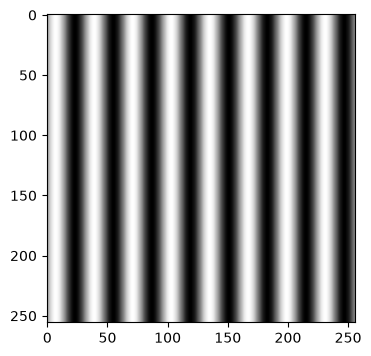

In [79]:
FFT_Inverse = np.abs(np.fft.ifft2(FFT_I))

plt.figure()
plt.imshow(FFT_Inverse, cmap="gray")

plt.show()

#### c. What happen in space domain if the magnitude of the zero frequency is put to zero in Fourier domain ?

The image becomes blurry

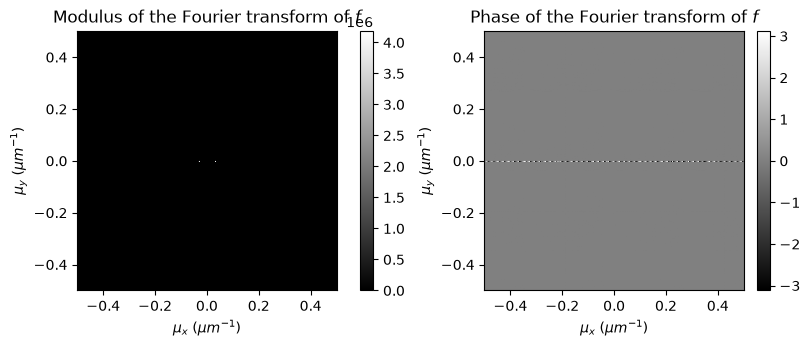

In [80]:
FFT_I_copy = np.copy(FFT_I)
FFT_I_copy[0, 0] = 0
DISPLAY_FFT_I=np.fft.fftshift(FFT_I_copy) # Shift of the spectrum FFTimg

MODULUS_DISPLAY_FFT_I=np.abs(DISPLAY_FFT_I)
PHASE_DISPLAY_FFT_I=np.angle(DISPLAY_FFT_I)

div = 1
extent = [-1/2 / div,1/2 / div,-1/2 / div,1/2 / div]

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(MODULUS_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar() # creates a color bar lookup table of the cmapxœ
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($\mu m^{-1}$)')
plt.ylabel(r'$\mu_y$ ($\mu m^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($\mu m^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($\mu m^{-1}$)')

plt.show()

#### d. What happen if all the values of the spectrum phase are put to zero before inverse FT ?

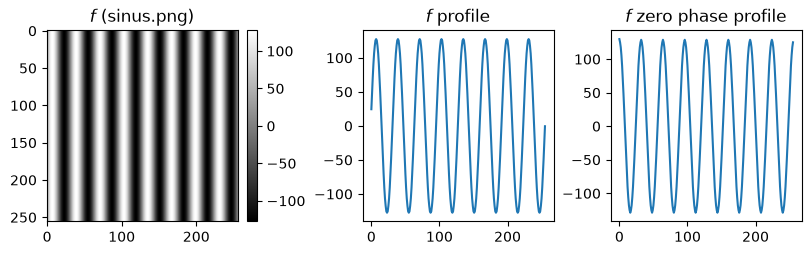

In [81]:
FFT_Inverse = np.real(np.fft.ifft2(FFT_I_copy))

FFT_zero_phase = np.abs(FFT_I_copy)
f_zero_phase = np.real(np.fft.ifft2(FFT_zero_phase))
# the zero phase makes it a cosine

plt.figure(layout='compressed')
plt.subplot(1,3,1)
plt.imshow(FFT_Inverse,'gray')
plt.colorbar()
plt.title('$f$ (sinus.png)')

plt.subplot(1,3,2)
plt.plot(FFT_Inverse[1,:])
plt.title('$f$ profile')


plt.subplot(1,3,3)
plt.plot(f_zero_phase[1,:])
plt.title('$f$ zero phase profile')

# plt.imshow(FFT_Inverse, cmap="gray")
plt.show()

### 1.3. +++ Do the same work on "sinus2.png".

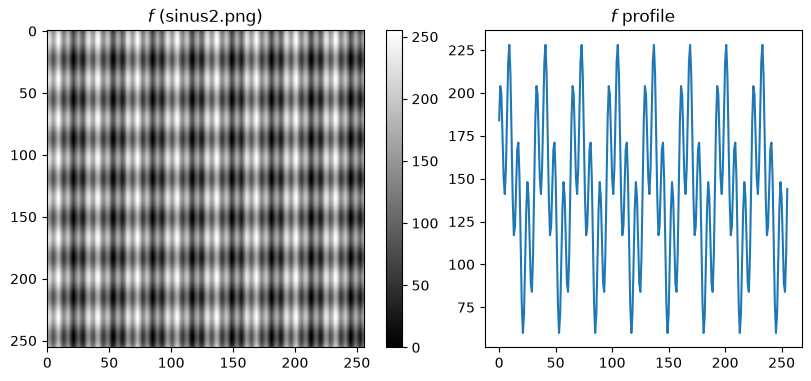

In [82]:
I=cv.imread('Lab1_Images/sinus2.png',cv.IMREAD_GRAYSCALE) 
I=np.double(I)

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(I,'gray')
plt.colorbar()
plt.title('$f$ (sinus2.png)')

plt.subplot(1,2,2)
plt.plot(I[1,:])
plt.title('$f$ profile')

plt.show()

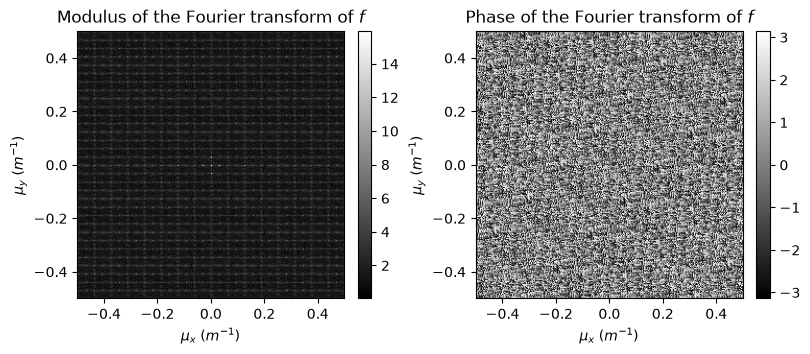

In [83]:
FFT_I_sinus2=np.fft.fft2(I)

DISPLAY_FFT_I=np.fft.fftshift(FFT_I_sinus2) # Shift of the spectrum FFTimg

MODULUS_DISPLAY_FFT_I=np.log(1 + np.abs(DISPLAY_FFT_I))
PHASE_DISPLAY_FFT_I=np.angle(DISPLAY_FFT_I)

mul = 1
extent = [-1/2 * mul,1/2 * mul,-1/2 * mul,1/2 * mul]

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(MODULUS_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar() # creates a color bar lookup table of the cmapxœ
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($m^{-1}$)')
plt.ylabel(r'$\mu_y$ ($m^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($m^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($m^{-1}$)')

plt.show()

### 1.4. +++ Display the image "Spectre3.png". Create an image which modulus would approximately be equal to "Spectre3.png". Are there several solutions ? Why ?

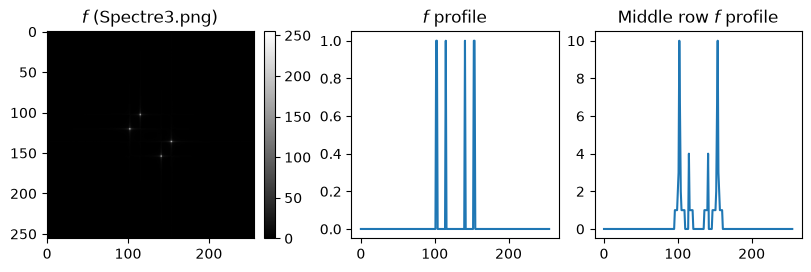

In [84]:
I=cv.imread('Lab1_Images/Spectre3.png',cv.IMREAD_GRAYSCALE) 
I=np.double(I)

plt.figure(layout='compressed')
plt.subplot(1,3,1)
plt.imshow(I,'gray')
plt.colorbar()
plt.title('$f$ (Spectre3.png)')

plt.subplot(1,3,2)
plt.plot(I[1,:])
plt.title('$f$ profile')

plt.subplot(1, 3, 3)
plt.plot(I[len(I)//2, :])
plt.title('Middle row $f$ profile')

plt.show()

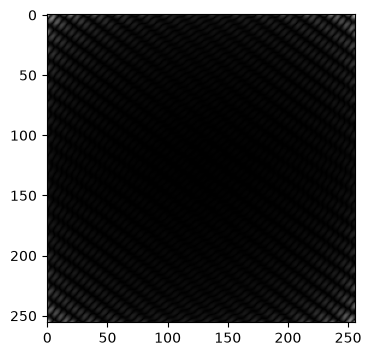

In [85]:
FFT_Inverse_2 = np.abs(np.fft.ifft2(I))

plt.figure()

plt.imshow(FFT_Inverse_2, cmap="gray")
plt.show()

## 2. Spectrum analysis

### 2.1. Measurements of periods

#### a. Display the image "text.png" and its spectrum

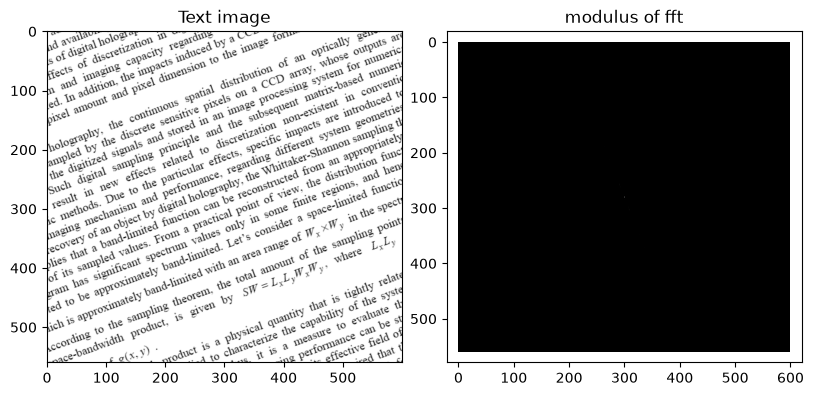

In [108]:
I=cv.imread('Lab1_Images/Text.png',cv.IMREAD_GRAYSCALE) 
I=np.double(I)

FFT_I=np.fft.fft2(I)
FFT_I[0,0]

DISPLAY_FFT_I=np.fft.fftshift(FFT_I)
MODULUS_DISPLAY_FFT_I=np.abs(DISPLAY_FFT_I)
extent_FFTI=[-1/2, 1/2-(1/I.shape[1]), -1/2, 1/2-(1/I.shape[0])]

plt.figure(layout="compressed")

plt.subplot(1, 2, 1)
plt.imshow(I, "gray")
plt.title("Text image")
plt.subplot(1, 2, 2)
plt.imshow(MODULUS_DISPLAY_FFT_I, cmap="gray")
plt.title("modulus of fft")
plt.axis('equal')
plt.show()

#### b. Analyze the spectrum and measure the lines periodicity. Check that your measurement is correct in the image.

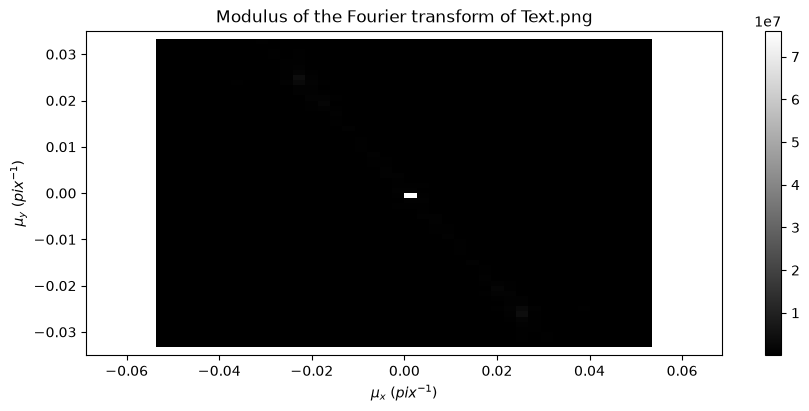

In [109]:
plt.figure(layout='compressed')

MODULUS_DISPLAY_FFT_I_zoom=MODULUS_DISPLAY_FFT_I[250:310,280:320]
extent_FFTI_zoom=[-3/56,3/56,-1/30,1/30]

plt.imshow(MODULUS_DISPLAY_FFT_I_zoom,extent=extent_FFTI_zoom,cmap='gray')
plt.axis('equal')
plt.colorbar()

plt.title('Modulus of the Fourier transform of Text.png')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)')
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')
plt.show()

 value is at (0.0009, -0.0004)[1.522e+08] 

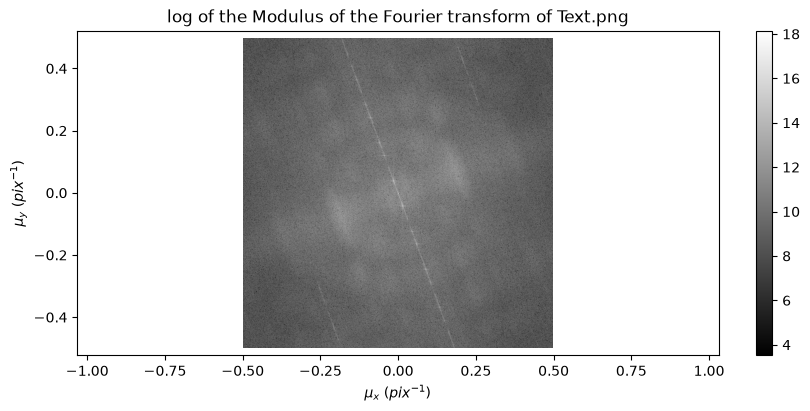

In [111]:
plt.figure(layout='compressed')
plt.imshow(np.log(MODULUS_DISPLAY_FFT_I+1),extent=extent_FFTI,cmap='gray');
plt.axis('equal')
plt.colorbar()
plt.title('log of the Modulus of the Fourier transform of Text.png')
plt.xlabel(r'$\mu_x$ ($pix^{-1}$)')
plt.ylabel(r'$\mu_y$ ($pix^{-1}$)')
plt.show()

#### c. If the coordinates of the peak in Fourier domain are located in the spectrum with an accuracy equal to ± 0.5 pixel, what is the accuracy on the period.

In [ ]:
On this spectrum, we can see two main peaks corresponding to 1 periodicity x the period of the lines in the text

#### d. Measure the rotation angle of the text.

In [ ]:
f0x=0.0156
f0y=0.0410
f0=np.sqrt(f0x*f0x+f0y*f0y)

T0=1/f0
print("The period pf the lines is {0:.1f}".format(T0), " in pixel")

The period pf the lines is 22.8  in pixel


#### e.	+++ What other measurements can be performed ?

### 2.2 The image `PolystyrenBead.png` is an interferometric image. The pixel size is 2.2 µm.

#### a. Using the image (space domain) measure the period of the carrier fringes.

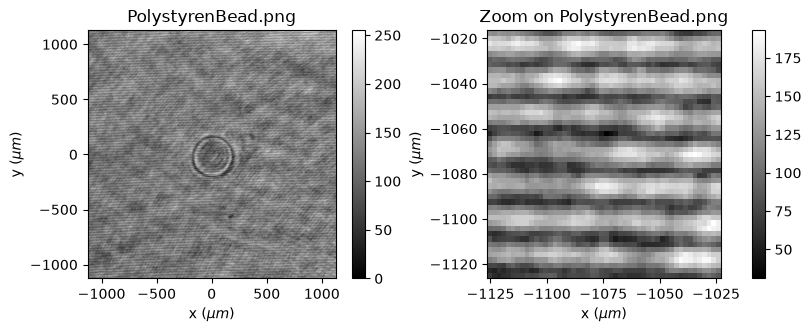

In [116]:
I=cv.imread('Lab1_Images/PolystyrenBead.png',cv.IMREAD_GRAYSCALE)
I=np.double(I)

pp=2.2
extent_I=[-I.shape[1]/2*pp, I.shape[1]/2*pp, -I.shape[0]/2*pp, I.shape[0]/2*pp]

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(I,'gray',extent=extent_I)
plt.colorbar()
plt.title('PolystyrenBead.png')
plt.xlabel(r'x ($\mu m$)')
plt.ylabel(r'y ($\mu m$)')
 
plt.subplot(1,2,2)
extent_I_zoom=[-I.shape[1]/2*pp, (47-I.shape[1]/2)*pp, -I.shape[0]/2*pp, (50-I.shape[0]/2)*pp]
plt.imshow(I[0:47,0:50],'gray',extent=extent_I_zoom)
plt.colorbar()
plt.title('Zoom on PolystyrenBead.png')
plt.xlabel(r'x ($\mu m$)') # puts a label for abscissa
plt.ylabel(r'y ($\mu m$)')
plt.show()

#### b. Make the same measurement using the spectrum (Fourier domain).

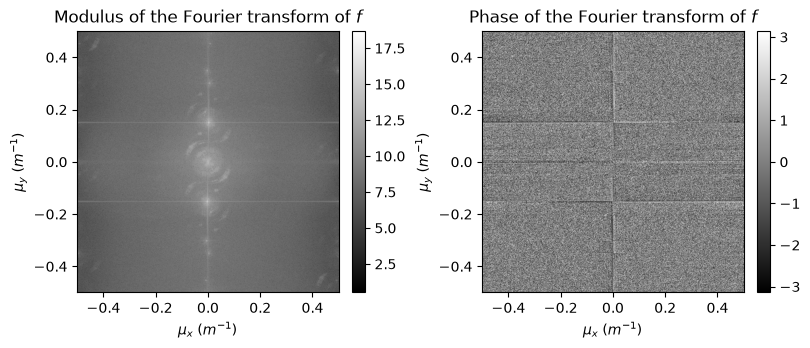

In [117]:
FFT_I_sinus2=np.fft.fft2(I)

DISPLAY_FFT_I=np.fft.fftshift(FFT_I_sinus2) # Shift of the spectrum FFTimg

MODULUS_DISPLAY_FFT_I=np.log(1 + np.abs(DISPLAY_FFT_I))
PHASE_DISPLAY_FFT_I=np.angle(DISPLAY_FFT_I)

mul = 1
extent = [-1/2 * mul,1/2 * mul,-1/2 * mul,1/2 * mul]

plt.figure(layout='compressed')
plt.subplot(1,2,1)
plt.imshow(MODULUS_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar() # creates a color bar lookup table of the cmapxœ
plt.title('Modulus of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($m^{-1}$)')
plt.ylabel(r'$\mu_y$ ($m^{-1}$)')

plt.subplot(1,2,2)
plt.imshow(PHASE_DISPLAY_FFT_I,extent=extent,cmap='gray')
plt.colorbar()
plt.title('Phase of the Fourier transform of $f$')
plt.xlabel(r'$\mu_x$ ($m^{-1}$)') 
plt.ylabel(r'$\mu_y$ ($m^{-1}$)')

plt.show()

In [119]:
f0x=0.0029
f0y=0.1514
f0=np.sqrt(f0x*f0x+f0y*f0y)
T0=1/f0
T0m=T0*pp
print("The period of the fringes is {0:.2f}".format(T0),' pix.')
print("The period of the fringes is {0:.2f}".format(T0m)," micron .")

The period of the fringes is 6.60  pix.
The period of the fringes is 14.53  micron .


#### d. Compute the accuracy of each measurement in space and frequency domain. Discuss on the results.

The period of the fringes is 6.60  pix.
The period of the fringes is 14.53  micron .


### 2.3. ++++ Same questions on  the image `ImSattNewYork.png`.

### 2.4. ++++ Select an image of your choice. Display its spectrum. Measure its periodicities.

## 3. ++++ Fourier Transforms of commonly used functions